# Phase I – ResNet-18 Error Analysis

This notebook investigates how the fine-tuned ResNet-18 binary classifier behaves on the test set. The goal is to go beyond overall accuracy and understand **which errors occur, where they occur, and whether image characteristics are associated with them**.


## 1. Setup and load the test data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import yaml

from pathlib import Path
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import models
from sklearn.metrics import confusion_matrix, classification_report

from src import MobilityAidDataset, eval_transform

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

test_df = pd.read_csv("data/test.csv")
print("Test set shape:", test_df.shape)
display(test_df.head())

Using device: cuda
Test set shape: (1952, 8)


,image_id,image_path,categories,num_objects,label,timestamp,time_difference,sequence_id
0,seq_1468843518.1616319190,Images_RGB\seq_1468843518.1616319190.png,"['person', 'person']",2,0,1.468844e+09,111.389498,1
1,seq_1468843518.2023388750,Images_RGB\seq_1468843518.2023388750.png,"['person', 'person']",2,0,1.468844e+09,0.040707,1
2,seq_1468843518.4288926630,Images_RGB\seq_1468843518.4288926630.png,"['person', 'person']",2,0,1.468844e+09,0.226554,1
3,seq_1468843518.7617701550,Images_RGB\seq_1468843518.7617701550.png,"['person', 'person', 'person']",3,0,1.468844e+09,0.332878,1
4,seq_1468843518.9438627540,Images_RGB\seq_1468843518.9438627540.png,"['person', 'person', 'person']",3,0,1.468844e+09,0.182092,1


### 1.1 Verify that the data splits do not share identical image paths

Before interpreting test performance, check whether any exact image paths occur in more than one split. This is a basic leakage check; it does not detect visually related frames from the same video.

In [2]:
def normalized_paths(dataframe):
    # Normalize slash direction so Windows-style and Unix-style paths compare consistently.
    return set(dataframe["image_path"].astype(str).str.replace("\\\\", "/", regex=False))

train_df = pd.read_csv("data/train.csv") if Path("data/train.csv").exists() else None
validation_df = pd.read_csv("data/validation.csv") if Path("data/validation.csv").exists() else None

test_paths = normalized_paths(test_df)

for split_name, split_df in [("Train", train_df), ("Validation", validation_df)]:
    if split_df is not None:
        overlap = test_paths.intersection(normalized_paths(split_df))
        print(f"{split_name} / Test overlap: {len(overlap)} images")
    else:
        print(f"{split_name} CSV not found.")

Train / Test overlap: 0 images
Validation / Test overlap: 0 images


## 2. Load the trained model and generate test predictions

The model is treated as a black box: this analysis uses its input images, predicted classes and output probabilities. It does not inspect the model's internal layers or learned features.

In [3]:
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)

checkpoint = torch.load("models/best_resnet18.pth", map_location=device)
model.load_state_dict(checkpoint)
model = model.to(device)
model.eval()

test_dataset = MobilityAidDataset(test_df, transform=eval_transform)
test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

print("Number of test images:", len(test_dataset))

Number of test images: 1952


In [4]:
all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy())

results_df = pd.DataFrame({
    "image_path": test_df["image_path"].values,
    "true_label": all_labels,
    "predicted_label": all_predictions,
    "probability_class_1": all_probabilities
})

results_df["correct"] = (
    results_df["true_label"] == results_df["predicted_label"]
)

print("Number of predictions:", len(results_df))
display(results_df.head())

Number of predictions: 1952


,image_path,true_label,predicted_label,probability_class_1,correct
0,Images_RGB\seq_1468843518.1616319190.png,0,0,0.001170,True
1,Images_RGB\seq_1468843518.2023388750.png,0,0,0.000236,True
2,Images_RGB\seq_1468843518.4288926630.png,0,0,0.000008,True
3,Images_RGB\seq_1468843518.7617701550.png,0,0,0.000702,True
4,Images_RGB\seq_1468843518.9438627540.png,0,0,0.000567,True


## 3. Overall model performance

This section establishes the baseline before investigating individual errors. Because the test set is imbalanced, class-wise metrics are important alongside accuracy.

### 3.1 Confusion matrix

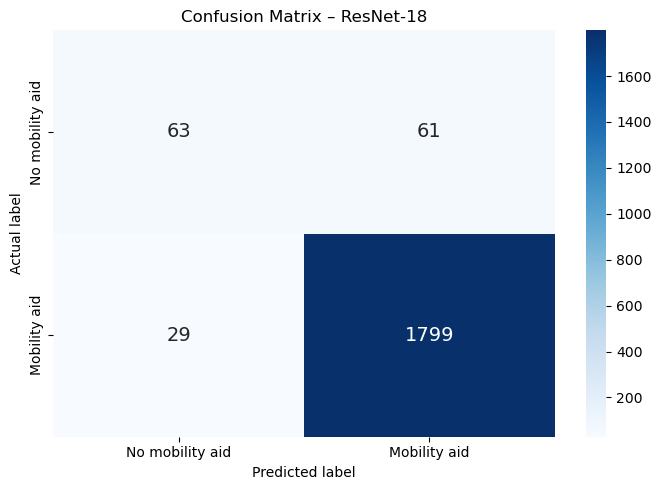

TN: 63 | FP: 61 | FN: 29 | TP: 1799


In [5]:
y_true = results_df["true_label"]
y_pred = results_df["predicted_label"]

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No mobility aid", "Mobility aid"],
    yticklabels=["No mobility aid", "Mobility aid"],
    annot_kws={"size": 14}
)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Confusion Matrix – ResNet-18")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")

**Confusion-matrix reading:** the saved analysis produced 63 true negatives, 61 false positives, 29 false negatives and 1,799 true positives. The model detects most mobility-aid images, but it misses a substantial share of the smaller no-mobility-aid class.

### 3.2 Precision, recall and F1-score by class

The classification report provides metrics separately for each class. Recall for Class 0 is especially important because it shows how many images without mobility aids are correctly recognized.

,No mobility aid (Class 0),Mobility aid (Class 1)
Precision,0.685,0.967
Recall,0.508,0.984
F1-score,0.583,0.976


Overall Model Accuracy: 0.954 (95.39%)


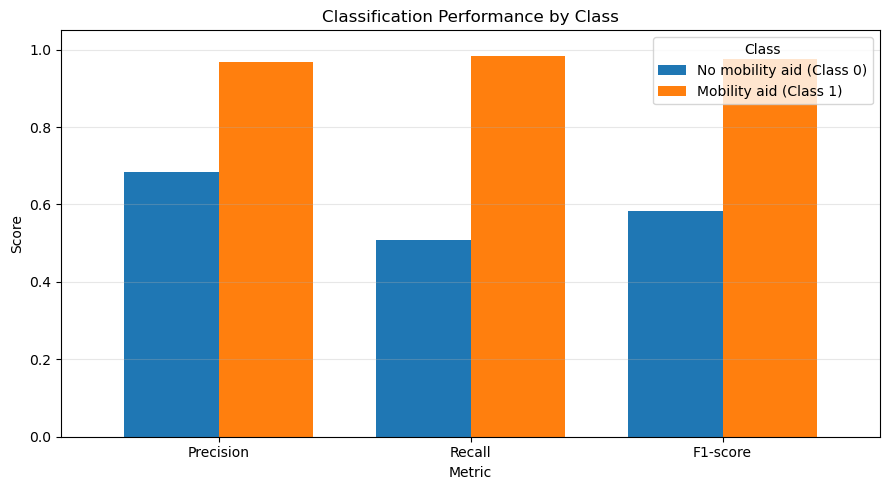

In [6]:
report = classification_report(
    y_true, y_pred, labels=[0, 1], output_dict=True, zero_division=0
)

metrics_df = pd.DataFrame({
    "No mobility aid (Class 0)": [
        report["0"]["precision"], report["0"]["recall"], report["0"]["f1-score"]
    ],
    "Mobility aid (Class 1)": [
        report["1"]["precision"], report["1"]["recall"], report["1"]["f1-score"]
    ]
}, index=["Precision", "Recall", "F1-score"])

display(metrics_df.round(3))

accuracy = report["accuracy"]

print(f"Overall Model Accuracy: {accuracy:.3f} ({accuracy * 100:.2f}%)")

ax = metrics_df.plot(kind="bar", figsize=(9, 5), width=0.75)
ax.set_title("Classification Performance by Class")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1.05)
ax.legend(title="Class")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.3 Class distribution

The class distribution helps explain why overall accuracy can look high even if performance on the smaller class is weaker.

,Class,Count,Percentage
0,No mobility aid,124,6.352459
1,Mobility aid,1828,93.647541


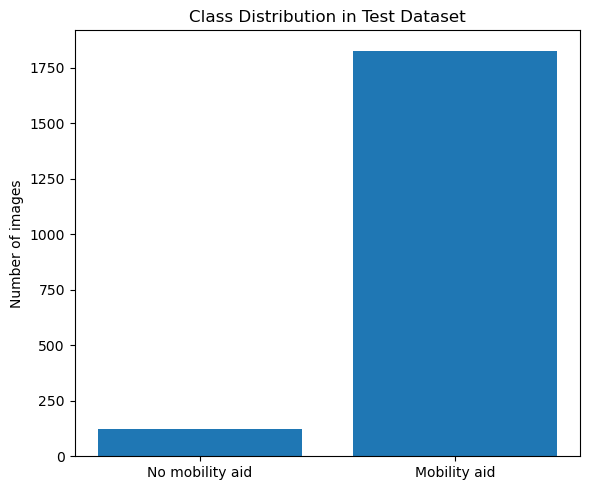

In [7]:
class_counts = test_df["label"].value_counts().reindex([0, 1], fill_value=0)
class_distribution = pd.DataFrame({
    "Class": ["No mobility aid", "Mobility aid"],
    "Count": [class_counts.loc[0], class_counts.loc[1]]
})
class_distribution["Percentage"] = (
    class_distribution["Count"] / class_distribution["Count"].sum() * 100
)
display(class_distribution)

plt.figure(figsize=(6, 5))
plt.bar(class_distribution["Class"], class_distribution["Count"])
plt.title("Class Distribution in Test Dataset")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Class-balance observation:** only 6.35% of the test images belong to Class 0. Therefore, the overall accuracy should not be interpreted without the class-wise precision, recall and F1-scores.

### 3.4 Prediction confidence by classification outcome

This plot compares the model's confidence in its predicted class across the four confusion-matrix outcomes.

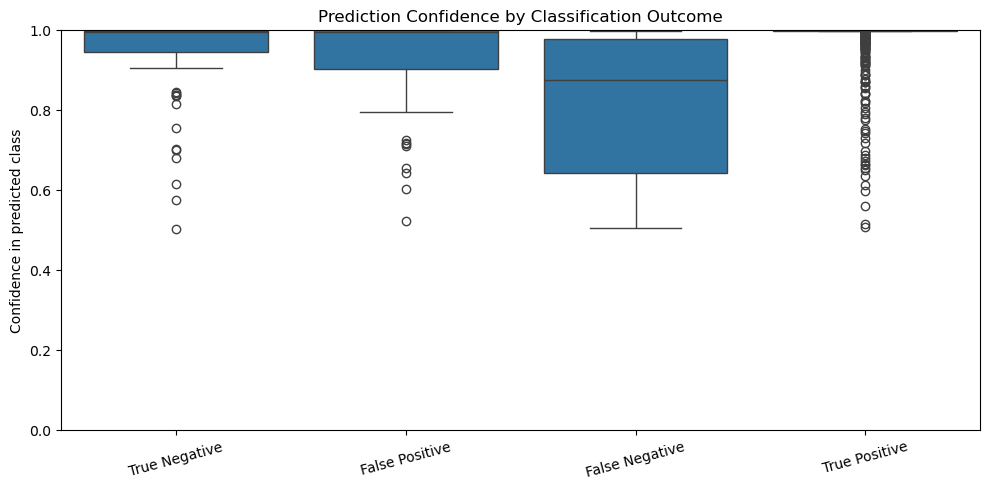

In [8]:
results_df["prediction_confidence"] = np.where(
    results_df["predicted_label"] == 1,
    results_df["probability_class_1"],
    1 - results_df["probability_class_1"]
)

results_df["outcome"] = np.select(
    [
        (results_df["true_label"] == 1) & (results_df["predicted_label"] == 1),
        (results_df["true_label"] == 0) & (results_df["predicted_label"] == 0),
        (results_df["true_label"] == 0) & (results_df["predicted_label"] == 1),
        (results_df["true_label"] == 1) & (results_df["predicted_label"] == 0),
    ],
    ["True Positive", "True Negative", "False Positive", "False Negative"],
    default="Unknown"
)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=results_df,
    x="outcome",
    y="prediction_confidence",
    order=["True Negative", "False Positive", "False Negative", "True Positive"]
)
plt.title("Prediction Confidence by Classification Outcome")
plt.xlabel("")
plt.ylabel("Confidence in predicted class")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 4. Inspect false positives and false negatives

- **False positive (FP):** the ground-truth label is 0, but the model predicts 1.
- **False negative (FN):** the ground-truth label is 1, but the model predicts 0.

The image galleries provide examples for visual inspection. They are samples, not a complete explanation of every error.

In [9]:
true_positives = results_df[
    (results_df["true_label"] == 1) & (results_df["predicted_label"] == 1)
].copy()

true_negatives = results_df[
    (results_df["true_label"] == 0) & (results_df["predicted_label"] == 0)
].copy()

false_positives = results_df[
    (results_df["true_label"] == 0) & (results_df["predicted_label"] == 1)
].copy()

false_negatives = results_df[
    (results_df["true_label"] == 1) & (results_df["predicted_label"] == 0)
].copy()


### 4.1 Visual inspection of misclassified images

Inspect the false-positive and false-negative galleries for recurring visual patterns. In the initial inspection, there were no obvious differences that explained all errors. Some errors appeared to occur close together in recording time, which motivated the temporal analysis in the next section.

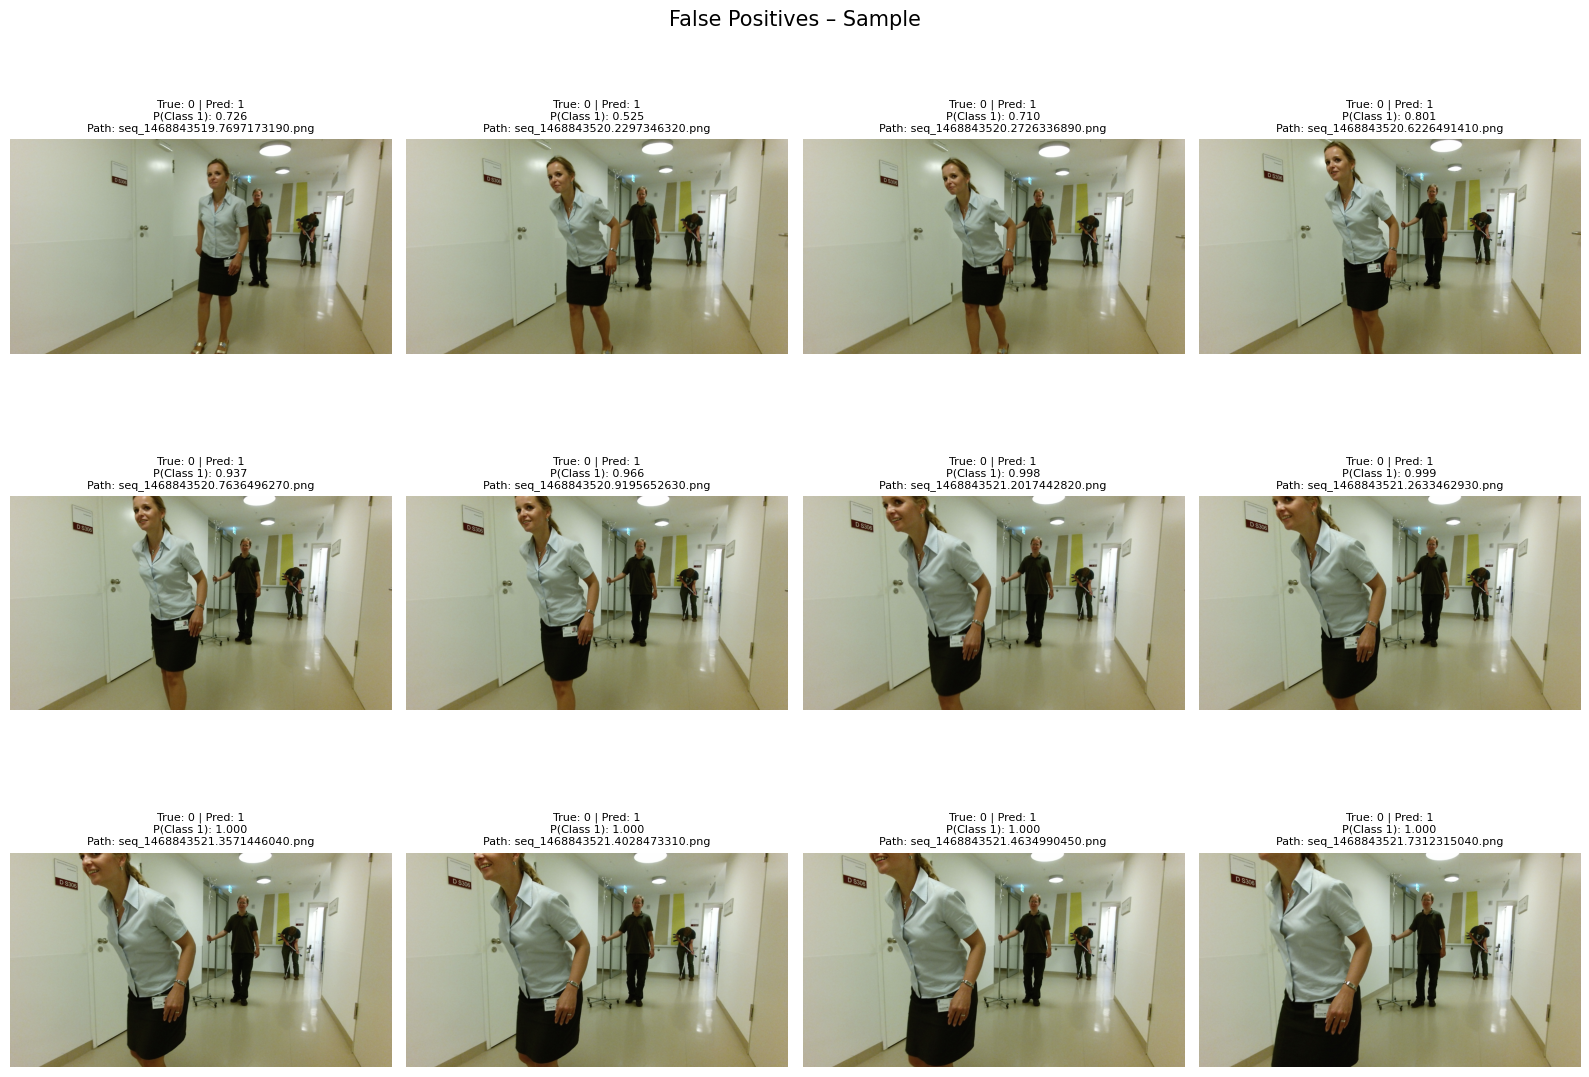

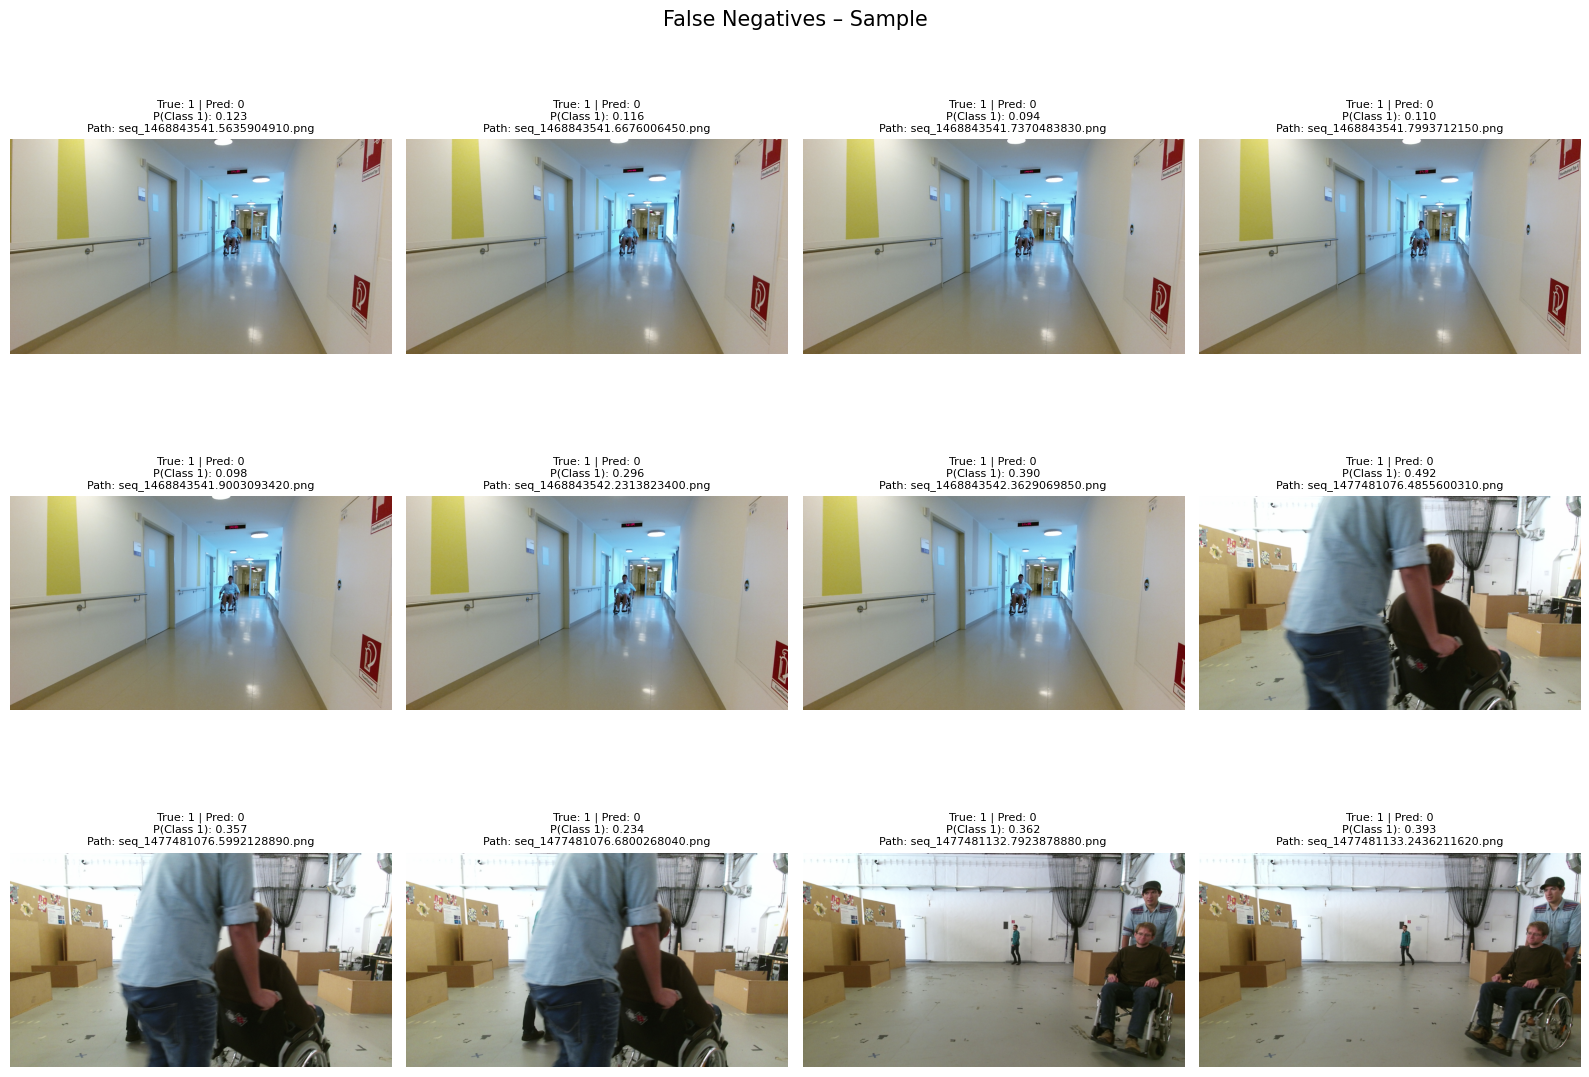

In [10]:
def show_image_gallery(dataframe, title, n=12, columns=4):
    sample = dataframe.head(n)
    if sample.empty:
        print(f"No images to display: {title}")
        return
        
    rows = int(np.ceil(len(sample) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4 * rows)) # Höhe leicht erhöht für den Pfadtext
    axes = np.array(axes).reshape(-1)
    
    for ax, (_, row) in zip(axes, sample.iterrows()):
        with Image.open(row["image_path"]) as image_file:
            image = image_file.convert("RGB")
        ax.imshow(image)
        
        # Bildpfad für die Anzeige kürzen, falls er zu lang ist (extrahiert den Dateinamen)
        import os
        short_path = os.path.basename(row['image_path'])
        
        ax.set_title(
            f"True: {row['true_label']} | Pred: {row['predicted_label']}\n"
            f"P(Class 1): {row['probability_class_1']:.3f}\n"
            f"Path: {short_path}", # <--- Hier wird der Bildpfad hinzugefügt
            fontsize=8 # Schriftgröße minimal verringert für bessere Lesbarkeit des Pfads
        )
        ax.axis("off")
        
    for ax in axes[len(sample):]:
        ax.axis("off")
        
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()

show_image_gallery(false_positives, "False Positives – Sample", n=12)
show_image_gallery(false_negatives, "False Negatives – Sample", n=12)

**Visual-inspection note:** the initial galleries did not reveal one clear visual explanation for all errors. The observation that errors seemed to recur in some recording periods motivated the timestamp-based temporal exploration.

## 5. Exploratory temporal analysis

The image filenames contain timestamp-like values. These timestamps can be used to order frames and create **provisional recording segments** based on large time gaps.

**Important limitation:** a timestamp gap is only a heuristic. It does not prove the dataset's official sequence boundaries. The segments in this section must therefore be described as provisional, not as verified video sequences.

In [11]:
temporal_df = results_df.copy()
temporal_df["filename"] = temporal_df["image_path"].apply(
    lambda x: Path(x).stem
)
temporal_df["timestamp"] = temporal_df["filename"].apply(
    lambda x: float(x.replace("seq_", ""))
)

temporal_df = temporal_df.sort_values("timestamp").reset_index(drop=True)
temporal_df["time_difference"] = temporal_df["timestamp"].diff()


### 5.1 Create provisional recording segments

A new provisional segment starts whenever the gap to the previous timestamp exceeds 60 seconds. This threshold is an exploratory choice and can be changed.

In [12]:
GAP_THRESHOLD_SECONDS = 60

temporal_df["sequence_id"] = (
    temporal_df["time_difference"] > GAP_THRESHOLD_SECONDS
).cumsum()

sequence_overview = temporal_df.groupby("sequence_id").agg(
    number_of_images=("filename", "count"),
    start_time=("timestamp", "min"),
    end_time=("timestamp", "max"),
    errors=("correct", lambda x: (~x).sum()),
    accuracy=("correct", "mean")
)

sequence_overview["error_rate"] = 1 - sequence_overview["accuracy"]

print("Number of provisional recording segments:",
      temporal_df["sequence_id"].nunique())
display(sequence_overview)

Number of provisional recording segments: 5


,number_of_images,start_time,end_time,errors,accuracy,error_rate
sequence_id,,,,,,
0,154,1.468844e+09,1.468844e+09,63,0.590909,0.409091
1,327,1.477471e+09,1.477471e+09,0,1.000000,0.000000
2,579,1.477481e+09,1.477481e+09,0,1.000000,0.000000
3,615,1.477481e+09,1.477481e+09,25,0.959350,0.040650
4,277,1.477483e+09,1.477483e+09,2,0.992780,0.007220


### 5.2 Compare error rates across provisional segments

This comparison helps identify whether some timestamp-based segments contain a higher proportion of errors.

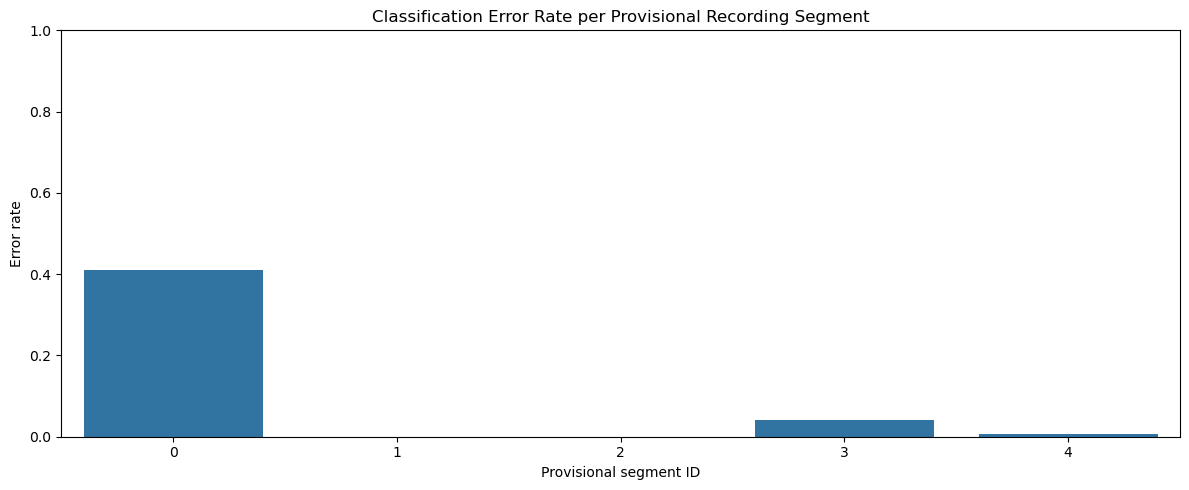

In [13]:
sequence_plot_df = sequence_overview.reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=sequence_plot_df, x="sequence_id", y="error_rate")
plt.title("Classification Error Rate per Provisional Recording Segment")
plt.xlabel("Provisional segment ID")
plt.ylabel("Error rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

**Temporal overview:** the current timestamp-gap rule produced five provisional recording segments. These are useful for exploration, but they are not verified dataset sequence labels.

### 5.3 Inspect images from the test set

Use this gallery as a quick visual reference. The interactive temporal plot below is more useful for inspecting a particular segment frame by frame.

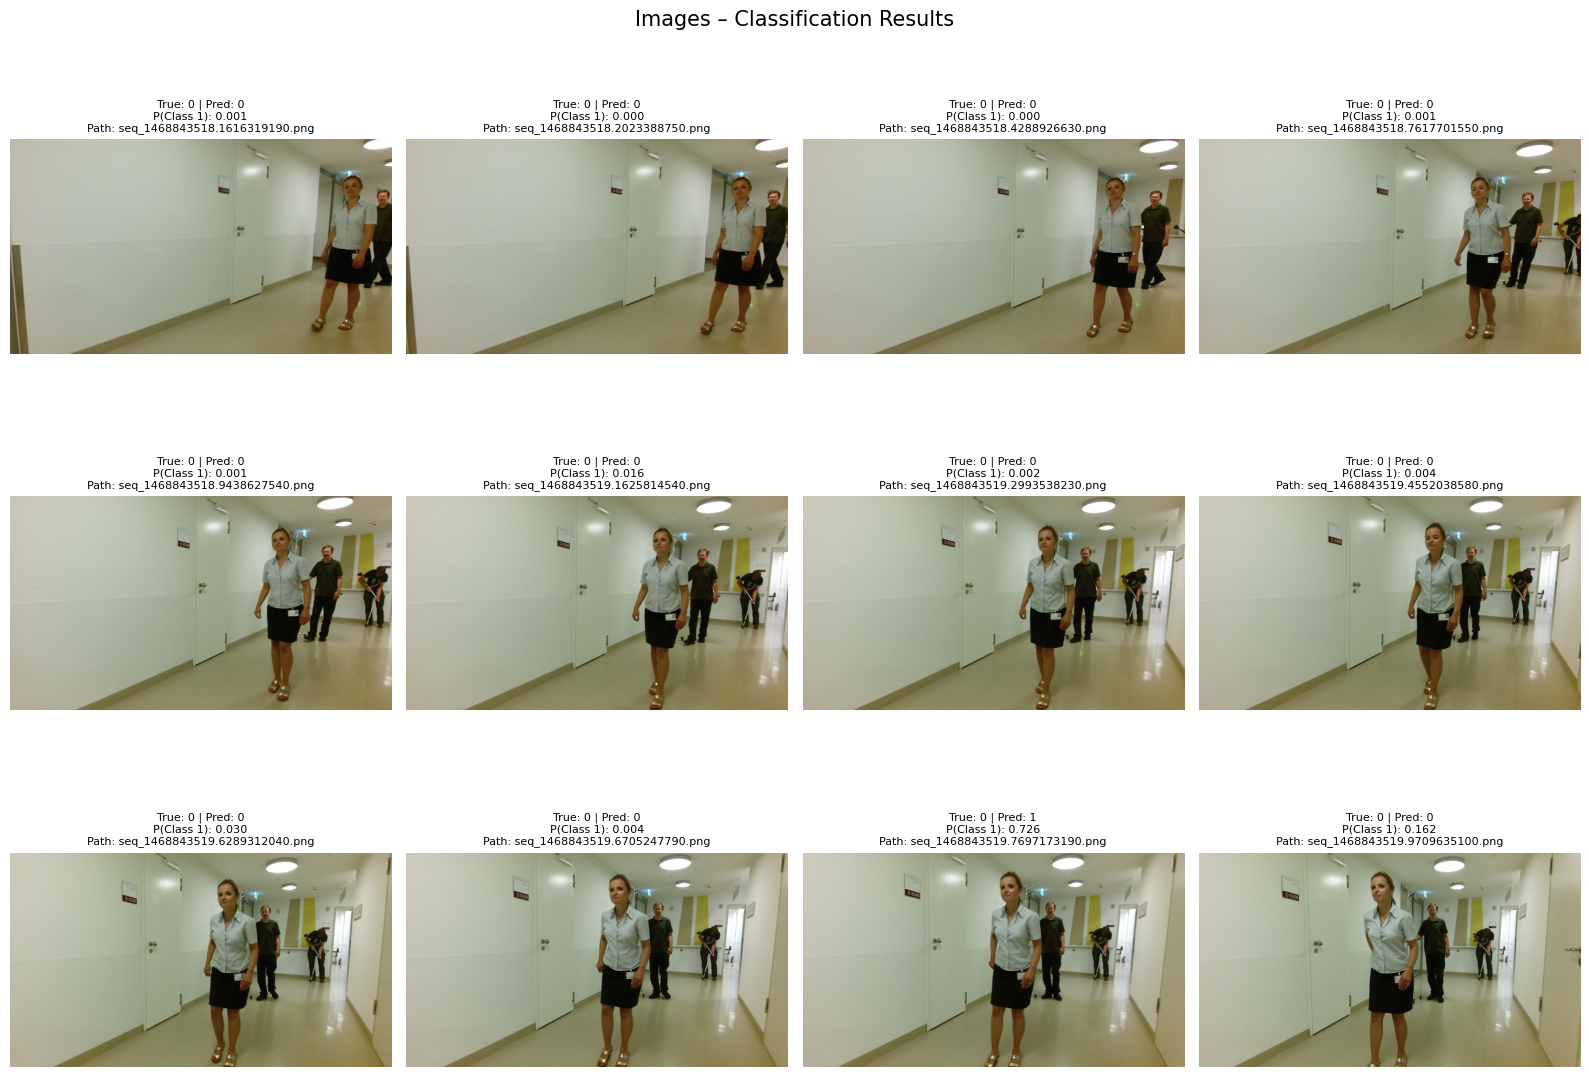

In [14]:
plot_df = results_df.copy()

show_image_gallery(
    plot_df,
    "Images – Classification Results",
    n=min(12, len(plot_df))
)

### 5.4 Find changes between incorrect and correct predictions

This analysis searches within each provisional segment for a later frame with the same ground-truth label but the opposite correctness outcome.

- **Incorrect → Correct:** an incorrect prediction is followed by a correct prediction.
- **Correct → Incorrect:** a correct prediction is followed by an incorrect prediction.

For each starting frame, the code records the nearest later matching frame within the configured time window. These are exploratory pairs; they are not necessarily immediately adjacent frames.

In [15]:

# Maximum time allowed between the two frames being compared.
# Set to None to search anywhere later in the same provisional segment.
MAX_COMPARISON_GAP_SECONDS = 10

ordered = temporal_df.sort_values(
    ["sequence_id", "timestamp"]
).reset_index(drop=True).copy()

transition_pairs = []

for sequence_id, group in ordered.groupby("sequence_id", sort=False):
    group = group.reset_index(drop=True)

    for start_idx, start_row in group.iterrows():
        # Find later frames with the same ground-truth label
        # but the opposite correctness outcome.
        later_candidates = group.iloc[start_idx + 1:]
        candidates = later_candidates[
            (later_candidates["true_label"] == start_row["true_label"]) &
            (later_candidates["correct"] != start_row["correct"])
        ]

        if MAX_COMPARISON_GAP_SECONDS is not None:
            candidates = candidates[
                (candidates["timestamp"] - start_row["timestamp"])
                <= MAX_COMPARISON_GAP_SECONDS
            ]

        if candidates.empty:
            continue

        # Nearest subsequent frame that changes correctness status.
        end_row = candidates.iloc[0]

        transition_pairs.append({
            "sequence_id": sequence_id,
            "start_image": start_row["image_path"],
            "end_image": end_row["image_path"],
            "true_label": int(start_row["true_label"]),
            "start_prediction": int(start_row["predicted_label"]),
            "end_prediction": int(end_row["predicted_label"]),
            "start_probability_class_1": float(start_row["probability_class_1"]),
            "end_probability_class_1": float(end_row["probability_class_1"]),
            "start_correct": bool(start_row["correct"]),
            "end_correct": bool(end_row["correct"]),
            "transition": (
                "Incorrect → Correct"
                if not start_row["correct"] and end_row["correct"]
                else "Correct → Incorrect"
            ),
            "elapsed_seconds": float(
                end_row["timestamp"] - start_row["timestamp"]
            ),
            "frames_apart": int(end_row.name - start_idx),
        })

transition_df = pd.DataFrame(transition_pairs)

if transition_df.empty:
    print("No correctness changes found within the selected time window.")
else:
    print("Number of matched frame pairs:", len(transition_df))
    display(
        transition_df["transition"]
        .value_counts()
        .rename_axis("Transition")
        .to_frame("Number of pairs")
    )
    


Number of matched frame pairs: 411


,Number of pairs
Transition,
Correct → Incorrect,366
Incorrect → Correct,45


### 5.5 Interactive temporal prediction path

The plot follows the model's probability for Class 1 over time within one provisional segment. The segment is selected by the largest number of errors by default.

- Green points: correct predictions.
- Red points: incorrect predictions.
- Dashed line: decision threshold of 0.5.
- Hover over a point to inspect its timestamp, labels and probability.
- Click a point to display that frame and its previous and next frames.

This makes it possible to inspect local changes in the image alongside changes in the model's prediction. A visual pattern in one segment should not automatically be generalized to the whole dataset.

In [ ]:
# Interactive Plotly path with click-to-inspect image display.
# If needed, install dependencies in a separate cell:
# %pip install plotly anywidget ipywidgets

import plotly.graph_objects as go
import ipywidgets as widgets
from io import BytesIO
from IPython.display import display, clear_output
from PIL import Image as PILImage

# Start with the segment containing the most images.
PATH_SEQUENCE_ID = int(
    sequence_overview["errors"].idxmax()
)

path_data = (
    temporal_df[temporal_df["sequence_id"] == PATH_SEQUENCE_ID]
    .sort_values("timestamp")
    .reset_index(drop=True)
    .copy()
)

if path_data.empty:
    print(f"No frames found for provisional segment {PATH_SEQUENCE_ID}.")
else:
    path_data["elapsed_time"] = (
        path_data["timestamp"] - path_data["timestamp"].min()
    )
    path_data["outcome"] = np.where(
        path_data["correct"], "Correct", "Incorrect"
    )

    fig = go.Figure()

    # Connect frames in temporal order.
    fig.add_trace(go.Scatter(
        x=path_data["elapsed_time"],
        y=path_data["probability_class_1"],
        mode="lines",
        name="Prediction path",
        line=dict(color="lightgrey", width=1.5),
        hoverinfo="skip"
    ))

    # Add one marker trace per outcome. Include image_path in customdata
    # so a click can retrieve the corresponding image from disk.
    for outcome, color in [("Correct", "#269B69"), ("Incorrect", "#D9534F")]:
        subset = path_data[path_data["outcome"] == outcome]

        fig.add_trace(go.Scatter(
            x=subset["elapsed_time"],
            y=subset["probability_class_1"],
            mode="markers",
            name=outcome,
            marker=dict(color=color, size=8, line=dict(color="white", width=0.5)),
            customdata=subset[[
                "filename", "true_label", "predicted_label", "correct", "image_path"
            ]].to_numpy(),
            hovertemplate=(
                "Time: %{x:.3f} s<br>"
                "P(Class 1): %{y:.3f}<br>"
                "Filename: %{customdata[0]}<br>"
                "True label: %{customdata[1]}<br>"
                "Predicted label: %{customdata[2]}<br>"
                "Correct: %{customdata[3]}<br>"
                "<i>Click to inspect this frame</i>"
                "<extra></extra>"
            )
        ))

    fig.add_hline(
        y=0.5,
        line_dash="dash",
        line_color="orange",
        annotation_text="Decision threshold (0.5)"
    )
    fig.update_layout(
        title=f"Temporal Prediction Path – Provisional Segment {PATH_SEQUENCE_ID}",
        xaxis_title="Elapsed time within segment (seconds)",
        yaxis_title="Probability of Class 1",
        yaxis=dict(range=[0, 1]),
        hovermode="closest",
        template="plotly_white",
        legend_title="Prediction outcome",
        height=520
    )

    # The output area updates whenever a marker is clicked.
    image_output = widgets.Output()

    def display_frame_and_neighbours(image_index):
        """Display the selected frame and its immediate neighbours."""
        indices = [i for i in [image_index - 1, image_index, image_index + 1]
                   if 0 <= i < len(path_data)]

        with image_output:
            clear_output(wait=True)
            print("Selected frame and neighbouring frames")
            print("The centre image is the point you clicked.")

            panels = widgets.HBox()
            panel_children = []

            for i in indices:
                row = path_data.iloc[i]
                image = PILImage.open(row["image_path"]).convert("RGB")
                image.thumbnail((420, 260))

                label = "SELECTED FRAME" if i == image_index else (
                    "PREVIOUS FRAME" if i < image_index else "NEXT FRAME"
                )
                status = "Correct" if bool(row["correct"]) else "Incorrect"
                metadata = widgets.HTML(
                    value=(
                        f"<b>{label}</b><br>"
                        f"{row['filename']}<br>"
                        f"True label: {int(row['true_label'])}<br>"
                        f"Prediction: {int(row['predicted_label'])}<br>"
                        f"P(Class 1): {float(row['probability_class_1']):.3f}<br>"
                        f"Outcome: {status}"
                    )
                )
                image_buffer = BytesIO()
                image.save(image_buffer, format="PNG")
                image_widget = widgets.Image(
                    value=image_buffer.getvalue(),
                    format="png",
                    width=420
                )
                panel_children.append(widgets.VBox([metadata, image_widget]))

            panels.children = tuple(panel_children)
            display(panels)

    def on_point_click(trace, points, selector):
        if not points.point_inds:
            return
        point_index = points.point_inds[0]
        image_path = trace.customdata[point_index][4]
        matching_indices = path_data.index[
            path_data["image_path"].astype(str) == str(image_path)
        ].tolist()
        if matching_indices:
            display_frame_and_neighbours(matching_indices[0])

    interactive_fig = go.FigureWidget(fig)
    for trace in interactive_fig.data:
        if trace.mode and "markers" in trace.mode:
            trace.on_click(on_point_click)

    display(interactive_fig)
    display(image_output)

    print("Frames in segment:", len(path_data))
    print("Incorrect predictions:", int((~path_data["correct"]).sum()))
    print("Segment duration (seconds):", round(path_data["elapsed_time"].max(), 3))

FigureWidget({
    'data': [{'hoverinfo': 'skip',
              'line': {'color': 'lightgrey', 'width': 1.5},
              'mode': 'lines',
              'name': 'Prediction path',
              'type': 'scatter',
              'uid': 'b5644747-d3a4-4107-be08-ada346c490f3',
              'x': array([0.00000000e+00, 4.07071114e-02, 2.67260790e-01, 6.00138426e-01,
                          7.82230854e-01, 1.00094962e+00, 1.13772202e+00, 1.29357195e+00,
                          1.46729946e+00, 1.50889301e+00, 1.60808539e+00, 1.80933166e+00,
                          1.97167826e+00, 2.03254938e+00, 2.06810284e+00, 2.11100197e+00,
                          2.46101737e+00, 2.60201788e+00, 2.75793338e+00, 3.04011250e+00,
                          3.10171437e+00, 3.19551277e+00, 3.24121547e+00, 3.30186725e+00,
                          3.56959963e+00, 3.64180350e+00, 3.70839119e+00, 3.77975082e+00,
                          3.90107274e+00, 4.20211959e+00, 4.74112129e+00, 4.96896863e+00,
    

Output()

Frames in segment: 154
Incorrect predictions: 63
Segment duration (seconds): 41.524


**Interactive inspection note:** the saved run selected the segment with the largest error count. It contained 154 frames, 63 incorrect predictions and covered approximately 41.5 seconds. Inspect the frames directly before attributing the errors to a particular visual condition.

## 6. Category-specific error analysis

The classifier predicts only the binary label, but the YAML annotations contain more detailed mobility-aid categories. These annotations can be used to compare false-negative rates across categories.

**Important:** categories may overlap. An image containing more than one mobility-aid type can contribute to multiple category groups. This is an analysis of binary classifier errors within annotated subsets, not a category classifier.

In [17]:

def annotation_path_for_image(image_path):
    image_path = Path(str(image_path).replace("\\\\", "/"))
    return image_path.parent.parent / "Annotations_RGB" / (image_path.stem + ".yml")

def extract_categories_safe(annotation_path):
    if not annotation_path.exists():
        return []
    with open(annotation_path, "r") as file:
        annotation = yaml.safe_load(file) or {}
    objects = annotation.get("annotation", {}).get("object", [])
    if isinstance(objects, dict):
        objects = [objects]
    return [obj.get("name", "unknown") for obj in objects]

category_results = results_df[[
    "image_path", "true_label", "predicted_label", "correct",
    "probability_class_1"
]].copy()

category_results["annotation_path"] = category_results["image_path"].apply(
    annotation_path_for_image
)
category_results["categories"] = category_results["annotation_path"].apply(
    extract_categories_safe
)

print("Images with an annotation:",
      category_results["categories"].apply(bool).sum(), "of", len(category_results))
display(category_results[["image_path", "categories"]].head())


Images with an annotation: 1952 of 1952


,image_path,categories
0,Images_RGB\seq_1468843518.1616319190.png,"[person, person]"
1,Images_RGB\seq_1468843518.2023388750.png,"[person, person]"
2,Images_RGB\seq_1468843518.4288926630.png,"[person, person]"
3,Images_RGB\seq_1468843518.7617701550.png,"[person, person, person]"
4,Images_RGB\seq_1468843518.9438627540.png,"[person, person, person]"


### 6.1 Compare false-negative rates across annotated categories

Each annotated category is evaluated independently. An image may belong to more than one category.

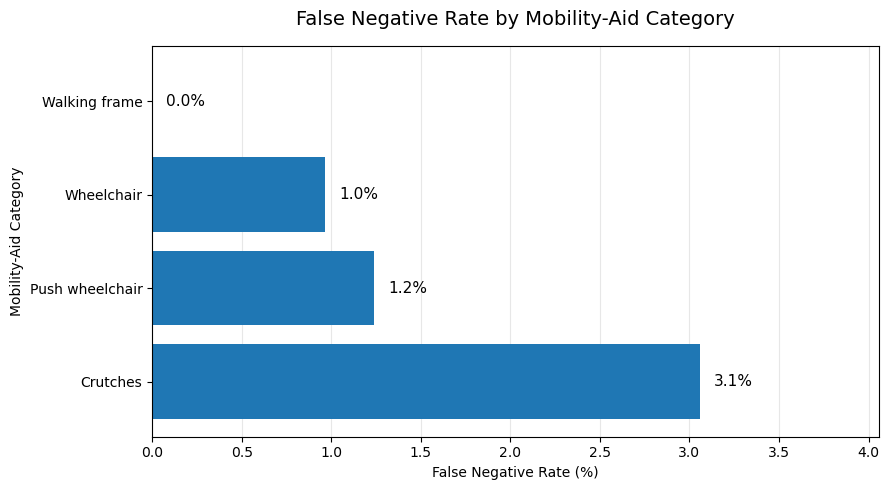

In [ ]:

mobility_aid_categories = [
    "wheelchair", "walking_frame", "crutches", "push_wheelchair"
]

category_rows = []
for category in mobility_aid_categories:
    subset = category_results[
        category_results["categories"].apply(lambda cats: category in cats)
    ]
    if len(subset) == 0:
        continue

    false_negatives_count = (
        (subset["true_label"] == 1) & (subset["predicted_label"] == 0)
    ).sum()
    true_positives_count = (
        (subset["true_label"] == 1) & (subset["predicted_label"] == 1)
    ).sum()

    category_rows.append({
        "category": category,
        "images_with_category": len(subset),
        "false_negatives": int(false_negatives_count),
        "true_positives": int(true_positives_count),
        "recall": true_positives_count / len(subset),
        "false_negative_rate": false_negatives_count / len(subset)
    })

category_error_df = pd.DataFrame(category_rows).sort_values(
    "false_negative_rate", ascending=False
)
display(category_error_df.round(3))


**Category-level observation:** crutches showed the highest false-negative rate in the category comparison. This motivated a closer inspection of crutches images. Because categories can overlap and group sizes differ, compare both rates and image counts.

### 6.2 Inspect an example of a missed crutches image

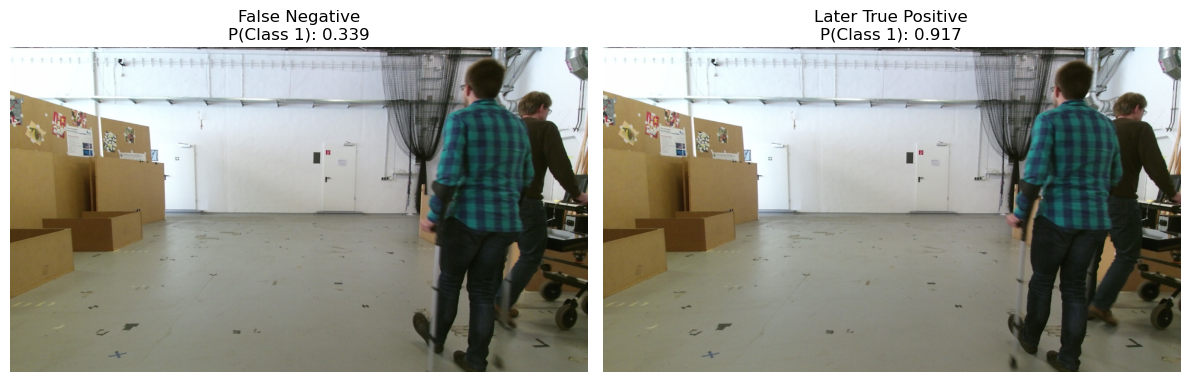

In [20]:
crutches_subset = category_results[
    category_results["categories"].apply(lambda cats: "crutches" in cats)
].copy()

false_negatives = crutches_subset[
    (crutches_subset["true_label"] == 1) &
    (crutches_subset["predicted_label"] == 0)
]
true_positives = crutches_subset[
    (crutches_subset["true_label"] == 1) &
    (crutches_subset["predicted_label"] == 1)
]

if false_negatives.empty:
    print("No false-negative crutches examples found.")
else:
    fn_row = false_negatives.sample(n=1, random_state=42).iloc[0]
    next_tp = true_positives[true_positives.index > fn_row.name]

    if next_tp.empty:
        print("No later true-positive crutches example found in the test data order.")
    else:
        tp_row = next_tp.iloc[0]
        fig, axes = plt.subplots(1, 2, figsize=(12, 6))
        for ax, row, title in [
            (axes[0], fn_row, "False Negative"),
            (axes[1], tp_row, "Later True Positive")
        ]:
            with Image.open(row["image_path"]) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(f"{title}\nP(Class 1): {row['probability_class_1']:.3f}")
            ax.axis("off")
        plt.tight_layout()
        plt.show()

### 6.1 Inspect an example of a missed crutches image

Crutches had the highest false-negative rate in the category comparison. This cell displays one false-negative example next to a later true-positive crutches image in the test data order. The pair is illustrative and does not establish that the images are consecutive frames from the same verified sequence.

## 7. Crutches image-quality analysis

The initial visual inspection suggested that some missed crutches images might look less sharp or noisier. This section tests that observation by comparing **False Negatives (FN)** with **True Positives (TP)** among images annotated with crutches.

The analysis measures:
- **Sharpness:** variance of the Laplacian; lower values can indicate less sharp images.
- **Brightness:** mean grayscale pixel intensity.
- **Contrast:** standard deviation of grayscale pixel intensity.

These are image-level measurements. They do not directly measure how clearly the crutches themselves are visible.

## 7. Crutches image-quality analysis

The initial visual inspection suggested that some missed crutches images might look less sharp or noisier. This section compares False Negatives (FN) with True Positives (TP) among images annotated with crutches.

We examine resolution, sharpness, brightness and contrast. These are image-level measurements and do not directly measure how clearly the crutches themselves are visible.

### 7.1 Compare image resolution

In [21]:
from PIL import Image
import numpy as np

def get_image_dimensions(image_path):
    try:
        with Image.open(image_path) as img:
            width, height = img.size
            return pd.Series({
                "width": width,
                "height": height,
                "total_pixels": width * height,
                "aspect_ratio": width / height
            })
    except Exception:
        return pd.Series({
            "width": np.nan, "height": np.nan,
            "total_pixels": np.nan, "aspect_ratio": np.nan
        })

dimensions = crutches_subset["image_path"].apply(get_image_dimensions)
crutches_subset = pd.concat(
    [crutches_subset.reset_index(drop=True), dimensions.reset_index(drop=True)],
    axis=1
)

**Resolution observation:** in the earlier analysis, the crutches images had the same resolution (960 × 540). Resolution therefore did not explain the observed difference in model outcomes.

### 7.2 Compare sharpness, brightness and contrast

In [28]:
import cv2
import numpy as np
import pandas as pd

def calculate_image_quality(image_path):
    try:
        image = cv2.imread(str(image_path))

        if image is None:
            return pd.Series({
                "sharpness": np.nan,
                "brightness": np.nan,
                "contrast": np.nan
            })

        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Sharpness: variance of the Laplacian
        sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()

        # Brightness: mean grayscale intensity
        brightness = gray.mean()

        # Contrast: standard deviation of grayscale intensity
        contrast = gray.std()

        return pd.Series({
            "sharpness": sharpness,
            "brightness": brightness,
            "contrast": contrast
        })

    except Exception:
        return pd.Series({
            "sharpness": np.nan,
            "brightness": np.nan,
            "contrast": np.nan
        })


quality_metrics = crutches_subset["image_path"].apply(calculate_image_quality)
crutches_subset = pd.concat(
    [crutches_subset.reset_index(drop=True),
     quality_metrics.reset_index(drop=True)],
    axis=1
)

crutches_subset["prediction_group"] = np.where(
    crutches_subset["predicted_label"] == crutches_subset["true_label"],
    "True Positive",
    "False Negative"
)


In [29]:
quality_comparison = crutches_subset[
    crutches_subset["prediction_group"].isin(["False Negative", "True Positive"])
].groupby("prediction_group")[
    ["sharpness", "brightness", "contrast"]
].agg(["count", "mean", "median", "std"])

display(quality_comparison.round(2))


sharpness                                               \
                     count    mean  median    std count    mean  median   
prediction_group                                                          
False Negative          14  258.52  260.67  16.86    14  258.52  260.67   
True Positive          444  299.64  315.47  50.37   444  299.64  315.47   

                                       ... contrast                            \
                    std count    mean  ...   median   std count   mean median   
prediction_group                       ...                                      
False Negative    16.86    14  258.52  ...    60.14  3.44    14  59.50  60.14   
True Positive     50.37   444  299.64  ...    55.80  5.66   444  56.44  55.80   

                                                  
                   std count   mean median   std  
prediction_group                                  
False Negative    3.44    14  59.50  60.14  3.44  
True Positive     5.66   444  56.44  55.80  5.66  

[2 rows x 36 columns]

['image_path', 'true_label', 'predicted_label', 'correct', 'probability_class_1', 'annotation_path', 'categories', 'width', 'height', 'total_pixels', 'aspect_ratio', 'sharpness', 'brightness', 'contrast', 'prediction_group']


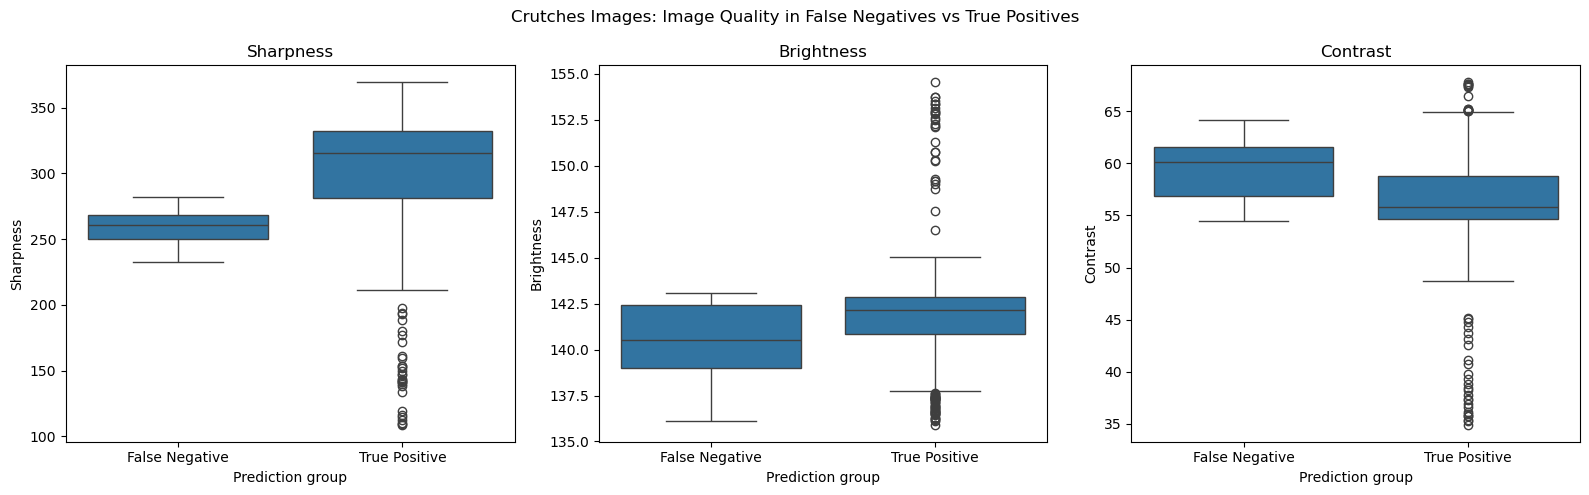

In [30]:
crutches_subset = crutches_subset.loc[
    :, ~crutches_subset.columns.duplicated()
].copy()
quality_plot_df = crutches_subset[
    crutches_subset["prediction_group"].isin(
        ["False Negative", "True Positive"]
    )
].copy()

print(crutches_subset.columns.tolist())

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric, title in zip(
    axes,
    ["sharpness", "brightness", "contrast"],
    ["Sharpness", "Brightness", "Contrast"]
):
    sns.boxplot(
        data=quality_plot_df,
        x="prediction_group",
        y=metric,
        order=["False Negative", "True Positive"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Prediction group")
    ax.set_ylabel(metric.capitalize())

plt.suptitle(
    "Crutches Images: Image Quality in False Negatives vs True Positives"
)
plt.tight_layout()
plt.show()

**Sharpness observation from the earlier analysis:** median sharpness was approximately 260.67 for false negatives and 315.47 for true positives. This is consistent with the hypothesis that missed images may be less sharp, but it does not show that sharpness causes the errors. Brightness and contrast are added here as further exploratory measurements.

### 7.3 Exploratory statistical comparison of sharpness

A one-sided Mann–Whitney U test compares the sharpness distributions, testing whether false negatives tend to have lower sharpness than true positives. Because video frames may be correlated, interpret the p-value cautiously.

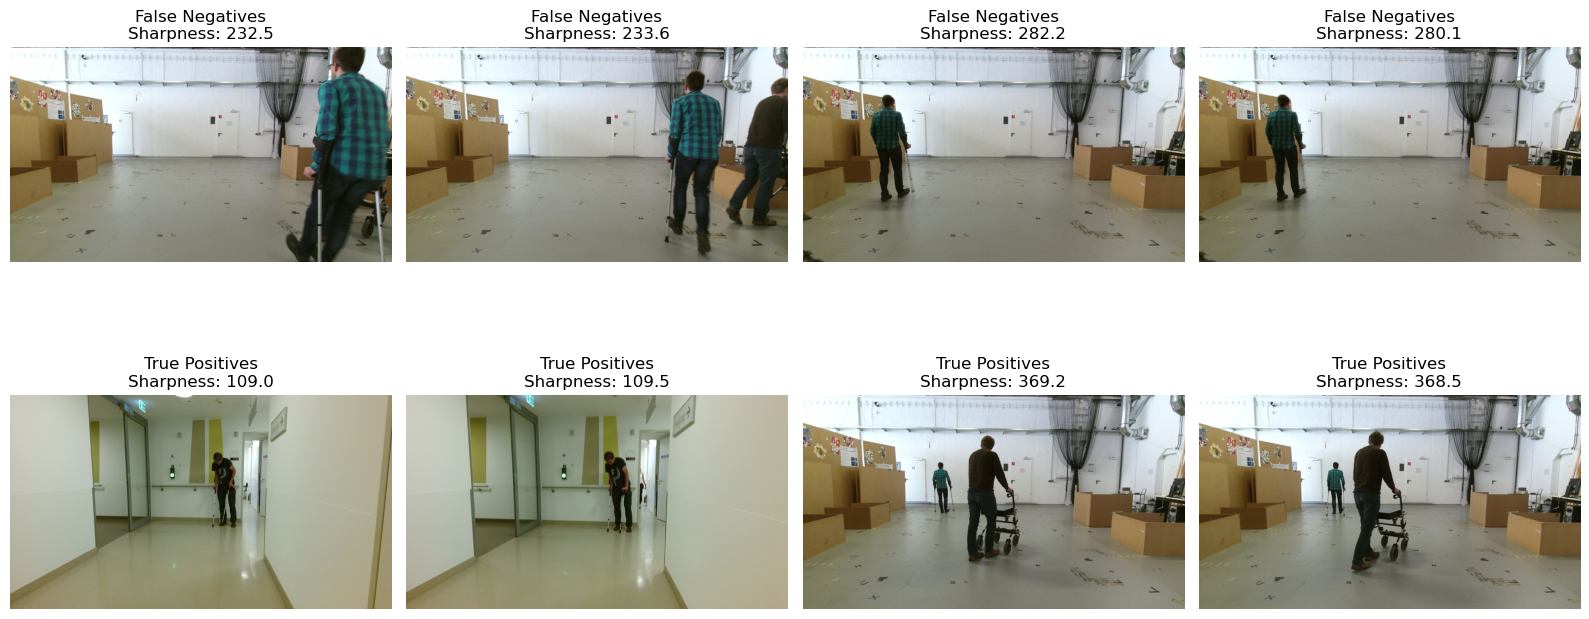

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for row_idx, (group, title) in enumerate([
    ("False Negative", "False Negatives"),
    ("True Positive", "True Positives")
]):
    subset = crutches_subset[
        crutches_subset["prediction_group"] == group
    ].dropna(subset=["sharpness"])

    examples = pd.concat([
        subset.nsmallest(2, "sharpness"),
        subset.nlargest(2, "sharpness")
    ])

    for col_idx, (_, image_row) in enumerate(examples.iterrows()):
        image = Image.open(
            image_row["image_path"]
        ).convert("RGB")

        axes[row_idx, col_idx].imshow(image)
        axes[row_idx, col_idx].set_title(
            f"{title}\nSharpness: {image_row['sharpness']:.1f}"
        )
        axes[row_idx, col_idx].axis("off")

plt.tight_layout()
plt.show()

## 8. Summary and conclusions

### Overall performance
**Overall performance**
The model achieved an overall accuracy of 95.4% on the 1,952 evaluated images. However, performance differed considerably between the two classes.
- Class 0 (no mobility aid): Precision 0.68, recall 0.51 and F1-score 0.58.
- Class 1 (mobility aid present): Precision 0.97, recall 0.98 and F1-score 0.98.
The model performed considerably better at identifying images containing mobility aids than images without them. It correctly classified 1,799 out of 1,828 Class 1 images, but only 63 out of 124 Class 0 images.

The dataset was highly imbalanced, with 93.6% of images belonging to Class 1 and only 6.4% to Class 0. This means that the high overall accuracy is largely influenced by the dominant class and does not fully reflect the weaker performance on Class 0. Therefore, accuracy alone is not sufficient to evaluate the model.

### Prediction errors
The confusion matrix showed 61 false positives and 29 false negatives.

Visual inspection of the false-positive and false-negative galleries did not reveal one clear visual characteristic that consistently explained the incorrect predictions.

This could indicate that the model sometimes responds to other visual elements in the scene, rather than exclusively to mobility aids. However, the annotations and visual inspection do not establish a specific explanation for these errors.

### Temporal behaviour
Based on timestamp gaps, the evaluated images were divided into five provisional recording segments.

The temporal analysis showed that errors were not equally distributed across these segments. Segment 0 contained the highest number of errors, while Segment 3 contained the most images. The interactive temporal visualization of Segment 3 showed that incorrect predictions appeared in clusters rather than being distributed completely randomly.

The consecutive-frame analysis identified 41 prediction transitions:
- FN → TP: 13
- TP → FN: 15
- FP → TN: 7
- TN → FP: 6
This demonstrates that predictions sometimes changed between immediately consecutive frames, even when the frames were recorded only fractions of a second apart. The average time between transitions ranged from approximately 0.07 to 0.20 seconds, depending on the transition type.

The interactive frame inspection allowed us to compare the previous, current and next frames alongside their predictions and confidence scores. This made it easier to identify local changes in prediction behaviour. In Segment 0, visual inspection suggested that a particular type of image might be repeatedly misclassified.

Overall, the temporal analysis revealed that prediction errors can occur in close proximity and that predictions may change considerably between nearby frames. However, the provisional nature of the segments means that these observations should be interpreted with caution.

### Category-specific errors
Category-specific errors
Among the annotated mobility-aid categories, crutches had the highest false-negative rate.

Crutches accounted for 14 of the 29 false negatives, meaning that almost half of all false negatives occurred in images containing this category.

However, the categories are not mutually exclusive. An image can contain multiple mobility-aid categories and therefore contribute to several category-specific groups. Consequently, the category counts should not be added together, and the results do not necessarily indicate that one category is inherently more difficult to recognize than another.

### Crutches image quality
False-negative images had lower average and median sharpness than true-positive images. However, the distributions overlapped considerably, meaning that some correctly classified images also had relatively low sharpness values.

Brightness and contrast showed only small differences between the two groups.

These results suggest a possible association between lower image sharpness and false-negative predictions for crutches. However, the measurements do not establish that image sharpness caused the classification errors. They also do not directly measure how clearly the mobility aid is visible in an image.

### Limitations

Several limitations need to be considered when interpreting these findings:
- **Provisional recording segments**: The five segments were identified using timestamp gaps. They are not verified recording or sequence IDs.
- **Correlated video frames**: Consecutive or nearby frames are highly related and should not be treated as fully independent observations.
- **Image-quality measurements**: Sharpness, brightness and contrast describe general image characteristics but do not directly measure the visibility of the mobility aid.
- **No causal conclusions**: Differences between correctly and incorrectly classified images may suggest possible relationships, but they do not establish why a prediction was incorrect.
